In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf
import numpy as np
import os

from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping


In [ ]:
train_dir = "/content/drive/MyDrive/Mendeley_16Class_Dataset/train"
test_dir  = "/content/drive/MyDrive/Mendeley_16Class_Dataset/test"


In [ ]:
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)


Found 2560 images belonging to 16 classes.
Found 640 images belonging to 16 classes.


In [ ]:
input_tensor = Input(shape=(224, 224, 3))


In [ ]:
mobilenet = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_tensor=input_tensor
)

resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_tensor=input_tensor
)


/tmp/ipython-input-3946131735.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
for layer in mobilenet.layers:
    layer.trainable = False

for layer in resnet.layers:
    layer.trainable = False


In [ ]:
mob_features = GlobalAveragePooling2D()(mobilenet.output)
res_features = GlobalAveragePooling2D()(resnet.output)


In [ ]:
fused_features = Concatenate()([mob_features, res_features])


In [ ]:
x = Dense(256, activation="relu")(fused_features)
output = Dense(16, activation="softmax")(x)


In [ ]:
fusion_model = Model(
    inputs=input_tensor,
    outputs=output
)

fusion_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c

 Total params: 26,702,032 (101.86 MB)

 Trainable params: 856,336 (3.27 MB)

 Non-trainable params: 25,845,696 (98.59 MB)

In [ ]:
fusion_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
checkpoint_cb = ModelCheckpoint(
    filepath="/content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

earlystop_cb = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


In [ ]:
history = fusion_model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=20,
    callbacks=[checkpoint_cb, earlystop_cb]
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.3411 - loss: 2.3806 
Epoch 1: val_loss improved from inf to 0.86036, saving model to /content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 1234s 15s/step - accuracy: 0.3440 - loss: 2.3732 - val_accuracy: 0.8562 - val_loss: 0.8604
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8736 - loss: 0.7158
Epoch 2: val_loss improved from 0.86036 to 0.43228, saving model to /content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.8737 - loss: 0.7145 - val_accuracy: 0.9250 - val_loss: 0.4323
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9235 - loss: 0.3870
Epoch 3: val_loss improved from 0.43228 to 0.29042, saving model to /content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.9236 - loss: 0.3866 - val_accuracy: 0.9500 - val_loss: 0.2904
Epoch 4/20
80

In [ ]:
fusion_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras"
)


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = fusion_model.predict(test_gen)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes

accuracy = accuracy_score(y_true, y_pred_classes)
print(f"Fusion Test Accuracy: {accuracy * 100:.2f}%")

print(classification_report(
    y_true,
    y_pred_classes,
    target_names=list(test_gen.class_indices.keys()),
    digits=4
))


20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step
Fusion Test Accuracy: 97.81%
                   precision    recall  f1-score   support

       FreshApple     0.9756    1.0000    0.9877        40
      FreshBanana     1.0000    1.0000    1.0000        40
       FreshGrape     0.9091    1.0000    0.9524        40
       FreshGuava     1.0000    1.0000    1.0000        40
      FreshJujube     0.9756    1.0000    0.9877        40
      FreshOrange     1.0000    1.0000    1.0000        40
 FreshPomegranate     0.9512    0.9750    0.9630        40
  FreshStrawberry     1.0000    1.0000    1.0000        40
      RottenApple     1.0000    0.9500    0.9744        40
     RottenBanana     1.0000    0.9750    0.9873        40
      RottenGrape     1.0000    0.9000    0.9474        40
      RottenGuava     0.9756    1.0000    0.9877        40
     RottenJujube     1.0000    0.9500    0.9744        40
     RottenOrange     0.9756    1.0000    0.9877        40
RottenPomegranate     0.9474    0.9000    0.92

In [ ]:
ModelCheckpoint(
    filepath="/content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras",
    monitor="val_loss",
    save_best_only=True
)



In [ ]:
import os
os.path.exists("/content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras")


True

In [ ]:
import tensorflow as tf

fusion_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras"
)


In [ ]:
import numpy as np

y_pred = fusion_model.predict(test_gen)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())


20/20 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_true, y_pred_classes)
print(f"Fusion Test Accuracy: {accuracy * 100:.2f}%")


Fusion Test Accuracy: 97.81%


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred_classes,
    target_names=class_names,
    digits=4
)

print(report)


                   precision    recall  f1-score   support

       FreshApple     0.9756    1.0000    0.9877        40
      FreshBanana     1.0000    1.0000    1.0000        40
       FreshGrape     0.9091    1.0000    0.9524        40
       FreshGuava     1.0000    1.0000    1.0000        40
      FreshJujube     0.9756    1.0000    0.9877        40
      FreshOrange     1.0000    1.0000    1.0000        40
 FreshPomegranate     0.9512    0.9750    0.9630        40
  FreshStrawberry     1.0000    1.0000    1.0000        40
      RottenApple     1.0000    0.9500    0.9744        40
     RottenBanana     1.0000    0.9750    0.9873        40
      RottenGrape     1.0000    0.9000    0.9474        40
      RottenGuava     0.9756    1.0000    0.9877        40
     RottenJujube     1.0000    0.9500    0.9744        40
     RottenOrange     0.9756    1.0000    0.9877        40
RottenPomegranate     0.9474    0.9000    0.9231        40
 RottenStrawberry     0.9524    1.0000    0.9756       

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred_classes)
print(cm)


[[40  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 40  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 40  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 40  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 40  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 40  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 39  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0 40  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0 38  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 39  0  1  0  0  0  0]
 [ 0  0  4  0  0  0  0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 40  0  0  0  0]
 [ 0  0  0  0  1  0  0  0  0  0  0  0 38  1  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0 40  0  0]
 [ 0  0  0  0  0  0  2  0  0  0  0  0  0  0 36  2]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 40]]


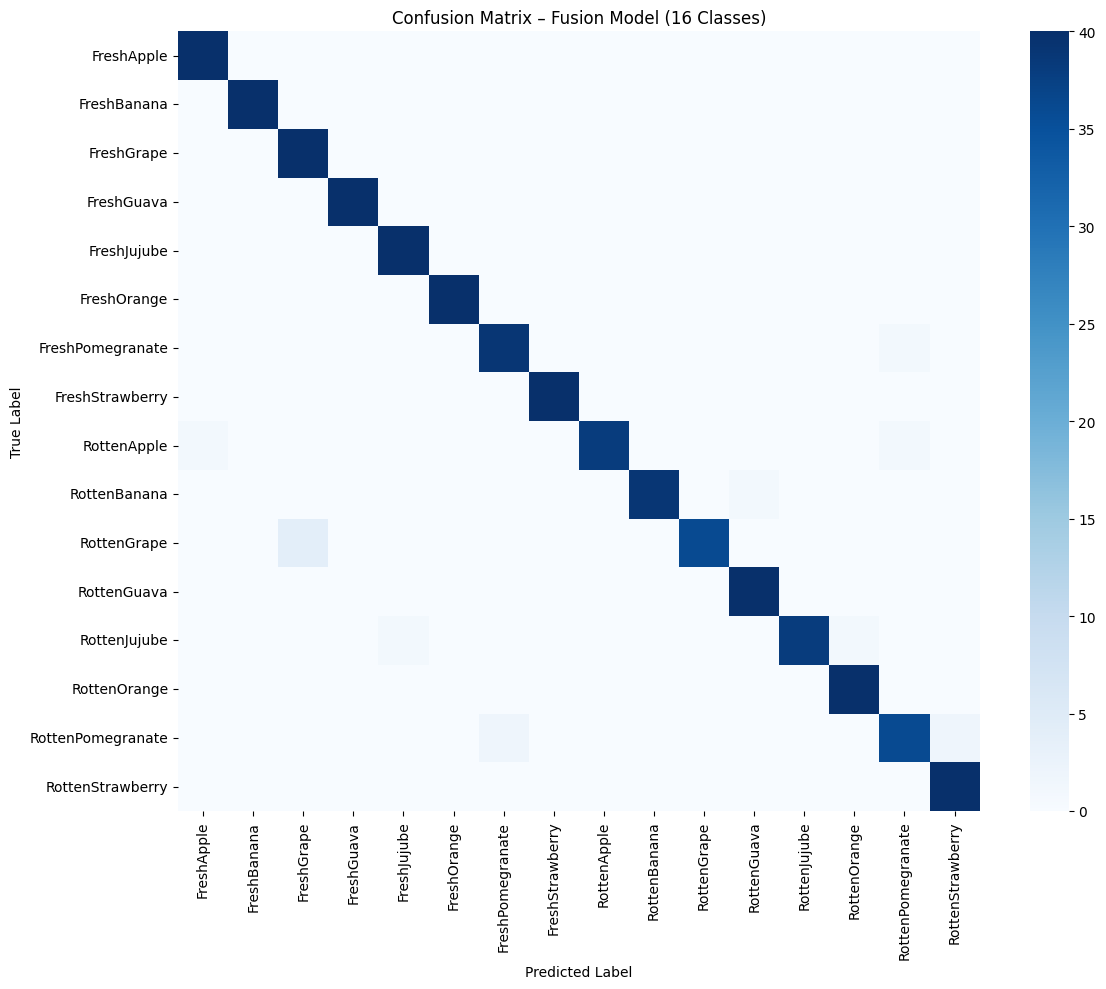

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot=False
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix – Fusion Model (16 Classes)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


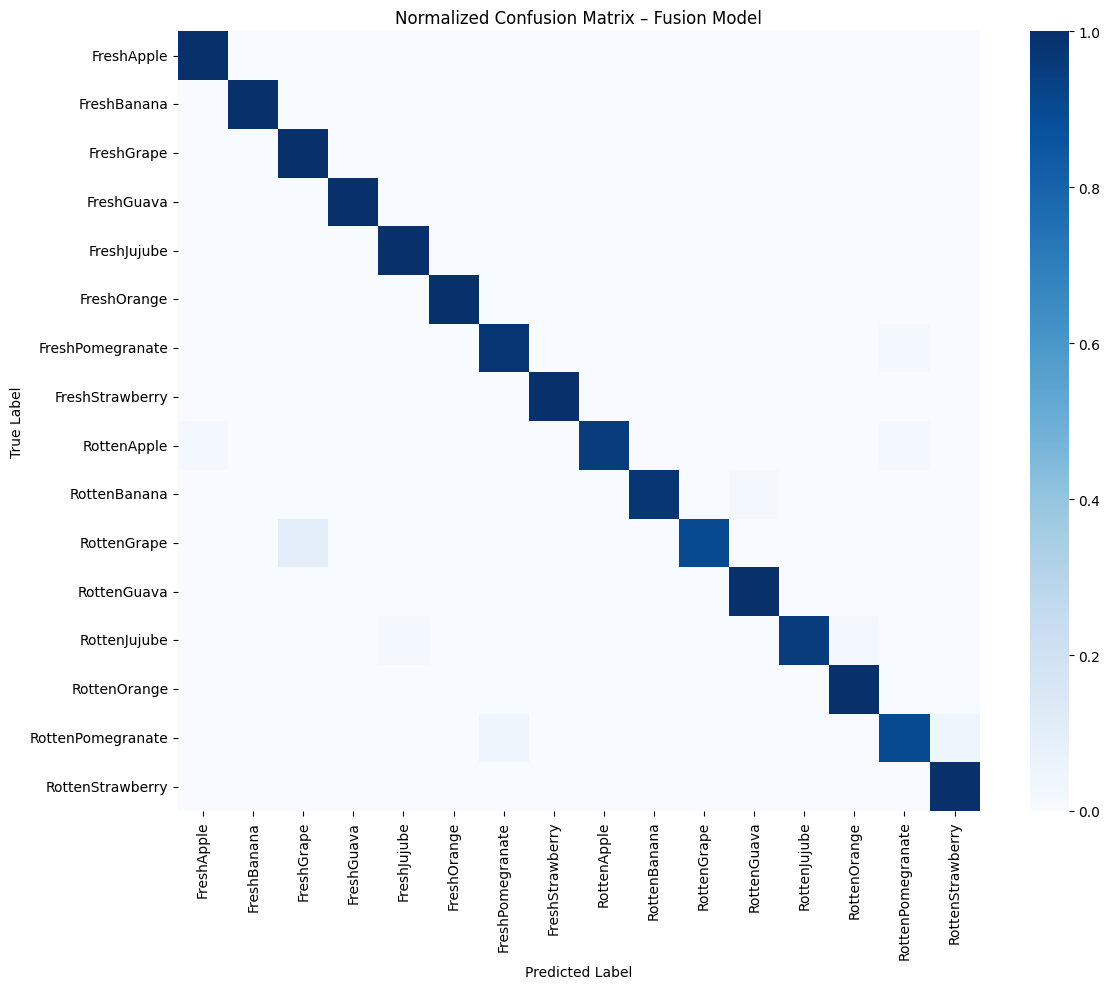

In [ ]:
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_norm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot=False
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized Confusion Matrix – Fusion Model")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import f1_score

macro_f1 = f1_score(y_true, y_pred_classes, average="macro")
weighted_f1 = f1_score(y_true, y_pred_classes, average="weighted")

print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")


Macro F1-score: 0.9780
Weighted F1-score: 0.9780
